In [ ]:
!pip install -q xgboost lightgbm

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset loaded successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Dataset loaded successfully!
Training samples: 455
Testing samples: 114
Number of features: 30


In [ ]:
models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=50,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        verbosity=-1,
        random_state=42,
        n_jobs=2
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    train_accuracy = accuracy_score(
        y_train, model.predict(X_train)
    )
    test_accuracy = accuracy_score(
        y_test, model.predict(X_test)
    )

    results.append({
        "Model": name,
        "Training Accuracy": round(train_accuracy, 4),
        "Testing Accuracy": round(test_accuracy, 4)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

            Model  Training Accuracy  Testing Accuracy
          Bagging                1.0            0.9386
    Random Forest                1.0            0.9561
         AdaBoost                1.0            0.9561
Gradient Boosting                1.0            0.9561
          XGBoost                1.0            0.9474
         LightGBM                1.0            0.9649


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


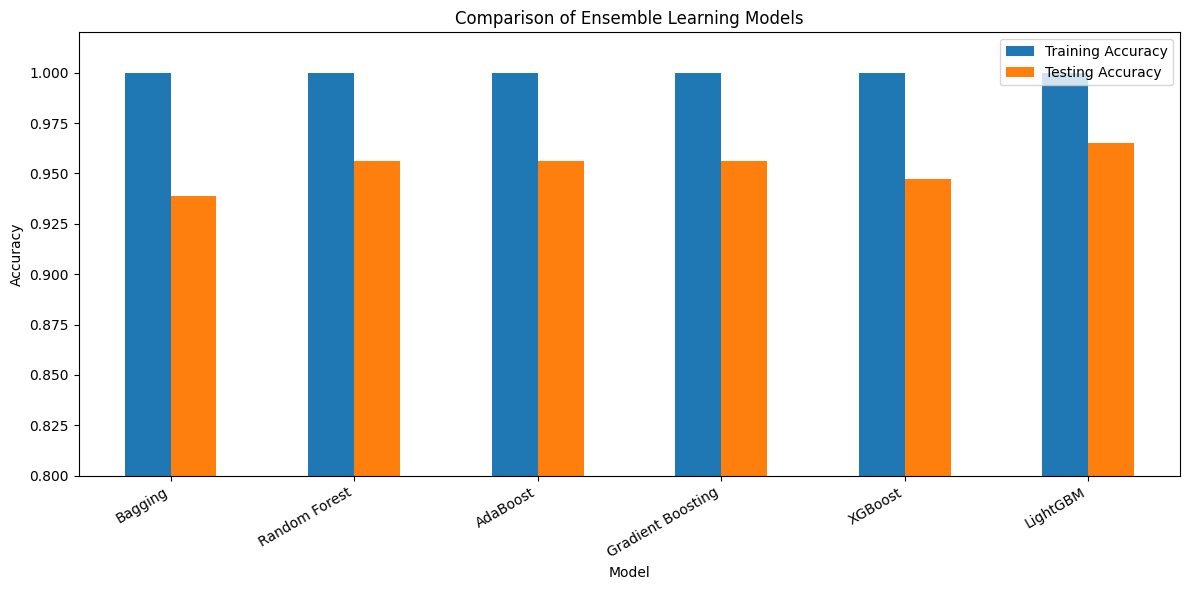

In [ ]:
results_df.set_index("Model")[
    ["Training Accuracy", "Testing Accuracy"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Ensemble Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0.80, 1.02)
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

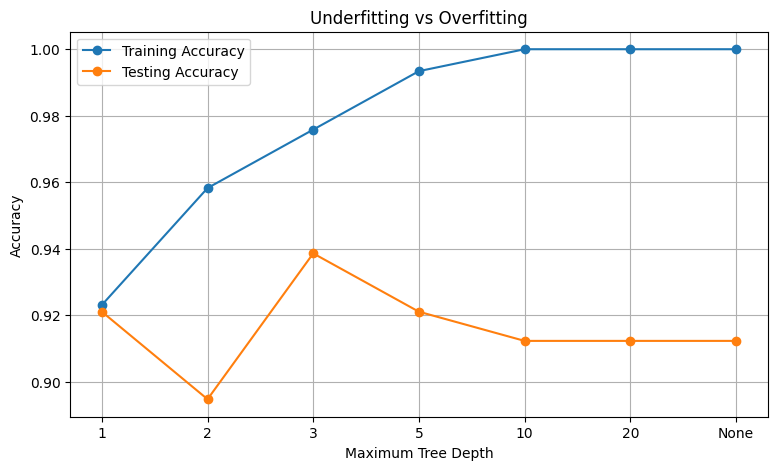

Depth=1: Train=0.923, Test=0.921
Depth=2: Train=0.958, Test=0.895
Depth=3: Train=0.976, Test=0.939
Depth=5: Train=0.993, Test=0.921
Depth=10: Train=1.000, Test=0.912
Depth=20: Train=1.000, Test=0.912
Depth=None: Train=1.000, Test=0.912


In [ ]:
depths = [1, 2, 3, 5, 10, 20, None]

train_scores = []
test_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_scores.append(
        accuracy_score(y_train, model.predict(X_train))
    )
    test_scores.append(
        accuracy_score(y_test, model.predict(X_test))
    )

plt.figure(figsize=(9, 5))
plt.plot(range(len(depths)), train_scores, marker="o",
         label="Training Accuracy")
plt.plot(range(len(depths)), test_scores, marker="o",
         label="Testing Accuracy")

plt.xticks(range(len(depths)), ["1", "2", "3", "5", "10", "20", "None"])
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Underfitting vs Overfitting")
plt.legend()
plt.grid(True)
plt.show()

for depth, train, test in zip(depths, train_scores, test_scores):
    print(f"Depth={depth}: Train={train:.3f}, Test={test:.3f}")

In [ ]:
models_reg = {
    "L1 Regularization": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=0.1,
            max_iter=5000,
            random_state=42
        )
    ),

    "L2 Regularization": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=0.1,
            max_iter=5000,
            random_state=42
        )
    ),

    "Weak Regularization": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=100,
            max_iter=5000,
            random_state=42
        )
    )
}

for name, model in models_reg.items():
    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )
    test_acc = accuracy_score(
        y_test, model.predict(X_test)
    )

    print(f"\n{name}")
    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Testing Accuracy:  {test_acc:.4f}")


L1 Regularization
Training Accuracy: 0.9846
Testing Accuracy:  0.9561

L2 Regularization
Training Accuracy: 0.9868
Testing Accuracy:  0.9737

Weak Regularization
Training Accuracy: 0.9934
Testing Accuracy:  0.9474


In [ ]:
best_model = models["XGBoost"]

y_pred = best_model.predict(X_test)

print("XGBoost Classification Report")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

XGBoost Classification Report
              precision    recall  f1-score   support

   malignant       0.95      0.90      0.93        42
      benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

